# 1. The vehicle and its kinematics

In this notebook, we describe the vehicle, build the kinematic model the
planner works with, and compare it with that of a car-like vehicle. A forklift
with two independently steered axles can rotate about a point that no car-like
vehicle can reach, and translate sideways while keeping its heading.

**Summary**

1. [Dimensions and footprint](#1)
2. [The kinematic model](#2)
3. [Steering modes](#3)
4. [Admissible velocities](#4)
5. [Minimum turning radius](#5)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm import DEFAULT_VEHICLE
from shfm.figures import save
from shfm.plotting import draw_pose

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

<a id='1'></a>
## 1. Dimensions and footprint

The vehicle studied here is an Adap2E platform fitted with forks. Its reference
point, whose pose the planner works with, is the centre of the rear
axle. That point is not the centre of the envelope, which must be taken into
account when drawing a footprint or configuring a collision checker.

In [2]:
v = DEFAULT_VEHICLE
print("length          %.4f m" % v.length)
print("width           %.4f m" % v.width)
print("wheelbase       %.4f m" % v.wheelbase)
print("rear axle at    %.4f m from the rear" % v.rear_axle_offset)
print("footprint area  %.3f m^2" % v.footprint_area())

length          3.6490 m
width           0.7000 m
wheelbase       1.3800 m
rear axle at    0.4845 m from the rear
footprint area  2.554 m^2


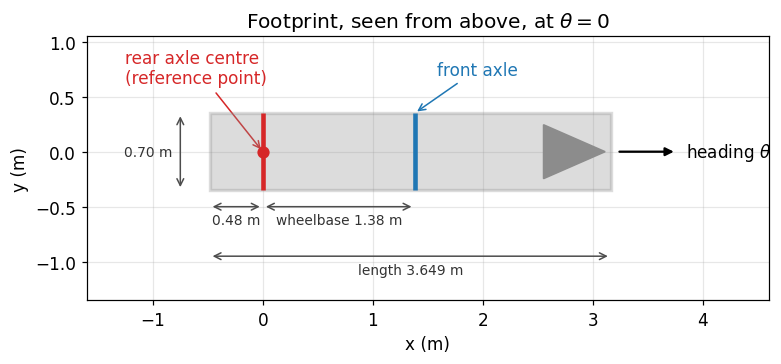

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
draw_pose(ax, 0, 0, 0, v, 1.0, color="0.55")    # in metres: zoom = 1
front = v.length - v.rear_axle_offset
for x_axle, colour in ((0.0, "tab:red"), (v.wheelbase, "tab:blue")):
    ax.plot([x_axle, x_axle], [-v.width / 2, v.width / 2], color=colour, lw=3,
            solid_capstyle="butt", zorder=8)
ax.plot(0, 0, "o", color="tab:red", ms=7, zorder=9)
ax.annotate("rear axle centre\n(reference point)", (0, 0), (-1.25, 0.62),
            arrowprops=dict(arrowstyle="->", color="tab:red"), color="tab:red")
ax.annotate("front axle", (v.wheelbase, v.width / 2), (v.wheelbase + 0.2, 0.7),
            arrowprops=dict(arrowstyle="->", color="tab:blue"), color="tab:blue")
ax.annotate("", (front + 0.6, 0), (front + 0.05, 0),
            arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
ax.text(front + 0.68, 0, "heading $\\theta$", va="center")

def dimension(x0, x1, y, text):
    ax.annotate("", (x0, y), (x1, y),
                arrowprops=dict(arrowstyle="<->", color="0.3", lw=1))
    ax.text(0.5 * (x0 + x1), y - 0.06, text, ha="center", va="top",
            fontsize=9, color="0.2")

dimension(-v.rear_axle_offset, 0, -0.5, "%.2f m" % v.rear_axle_offset)
dimension(0, v.wheelbase, -0.5, "wheelbase %.2f m" % v.wheelbase)
dimension(-v.rear_axle_offset, front, -0.95, "length %.3f m" % v.length)
ax.annotate("", (-0.75, -v.width / 2), (-0.75, v.width / 2),
            arrowprops=dict(arrowstyle="<->", color="0.3", lw=1))
ax.text(-0.82, 0, "%.2f m" % v.width, ha="right", va="center", fontsize=9,
        color="0.2")
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_xlim(-1.6, 4.6); ax.set_ylim(-1.35, 1.05); ax.grid(alpha=0.3)
ax.set_title("Footprint, seen from above, at $\\theta = 0$")
save(fig, "01_footprint"); plt.show()

The collision model does not use that rectangle directly. It covers it with a
chain of discs, which is the subject of notebook 2.

<a id='2'></a>
## 2. The kinematic model

We write $\theta$ for the heading, $\varphi$ for the front steering angle,
$\psi$ for the rear one, and $L$ for the wheelbase. The thesis writes
$\delta_F$ and $\delta_R$ for $\varphi$ and $\psi$, and $v$ for the speed of
the reference point (eq. (3.1)). Moving the reference point by an arc length
$\tau$ gives

$$
\begin{aligned}
x &\leftarrow x + \tau \cos(\theta + \psi) \\
y &\leftarrow y + \tau \sin(\theta + \psi) \\
\theta &\leftarrow \theta + \tau \cos\psi \,\frac{\tan\varphi - \tan\psi}{L}
\end{aligned}
$$

The factor $\cos\psi$ comes from $\tau$ being measured at the rear axle. Rolling
without slip gives both axles the same speed along the chassis, $\tau\cos\psi$,
and the rotation follows from the difference of their sideways speeds. Without
that factor the front wheels would slip sideways whenever the rear axle steers.

Two consequences follow. The heading rate depends on the *difference* of
the tangents, so steering both axles to the same angle leaves the
heading unchanged.
The direction of travel, moreover, is $\theta + \psi$, not $\theta$: the
vehicle moves at an angle to its heading. This is crab motion, which a
car-like model cannot express.

In [4]:

def step(q, phi, psi, tau, wheelbase):
    "One integration step of the model above."
    x, y, th = q
    c = np.cos(psi)
    return (x + tau * np.cos(th + psi),
            y + tau * np.sin(th + psi),
            th + tau * c * (np.tan(phi) - np.tan(psi)) / wheelbase)

def integrate(phi, psi, n=400, tau=0.02, wheelbase=None):
    wheelbase = wheelbase or v.wheelbase
    q = (0.0, 0.0, 0.0)
    out = [q]
    for _ in range(n):
        q = step(q, phi, psi, tau, wheelbase)
        out.append(q)
    return np.array(out)

<a id='3'></a>
## 3. Steering modes

Four regimes are usually distinguished, and they are fixed relations between
the two steering angles.
Each panel starts from the same pose, heading along $+x$, and drives four
metres forward with the front axle at its saturation of 0.5 rad, once to the
left and once to the right; the rear angle follows from the mode.

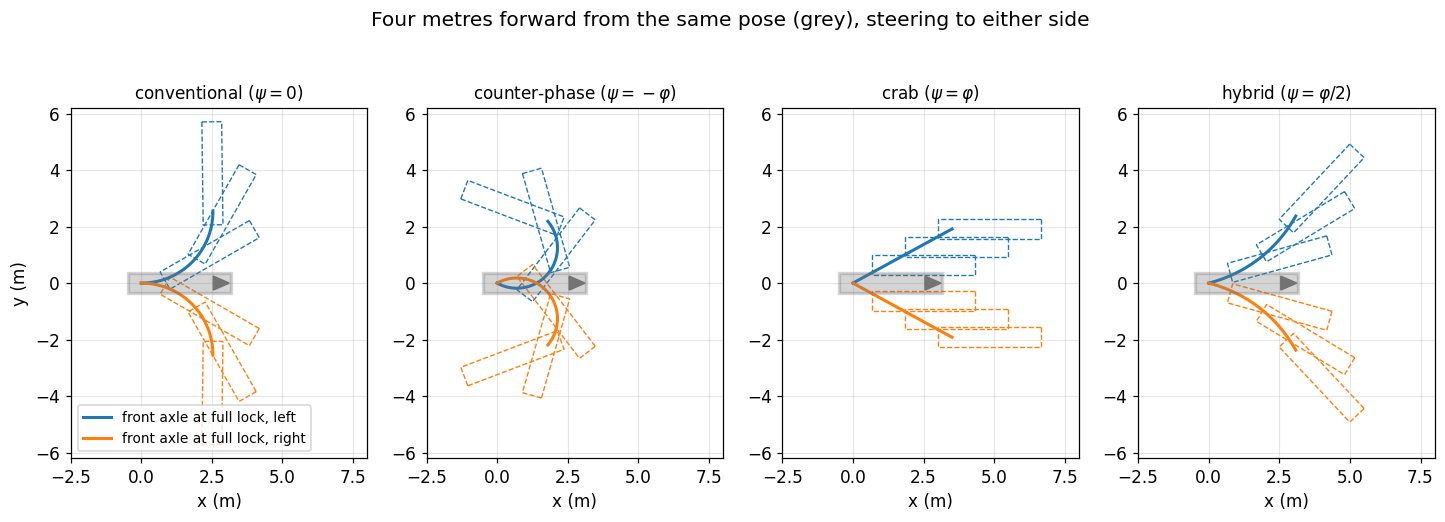

In [5]:
d = 0.5                                   # steering saturation, radians
travel = 4.0                              # metres, driven forward
modes = [("conventional ($\\psi = 0$)",          lambda phi: 0.0),
         ("counter-phase ($\\psi = -\\varphi$)", lambda phi: -phi),
         ("crab ($\\psi = \\varphi$)",           lambda phi: phi),
         ("hybrid ($\\psi = \\varphi / 2$)",     lambda phi: phi / 2)]
sides = [(d, "tab:blue", "front axle at full lock, left"),
         (-d, "tab:orange", "front axle at full lock, right")]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.9))
for ax, (name, rear) in zip(axes, modes):
    for phi, colour, label in sides:
        p = integrate(phi, rear(phi), n=int(round(travel / 0.02)))
        ax.plot(p[:, 0], p[:, 1], lw=2, color=colour, label=label)
        for i in np.linspace(0, len(p) - 1, 4).astype(int)[1:]:
            ax.add_patch(plt.Polygon(
                v.footprint_polygon(p[i, 0], p[i, 1], p[i, 2], 1.0),
                closed=True, fill=False, ls="--", ec=colour, lw=0.9))
    draw_pose(ax, 0, 0, 0, v, 1.0, color="0.45")
    ax.set_title(name, fontsize=11)
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_xlabel("x (m)")
    ax.set_xlim(-2.5, 8); ax.set_ylim(-6.2, 6.2)
axes[0].set_ylabel("y (m)")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Four metres forward from the same pose (grey), "
             "steering to either side", y=1.0)
save(fig, "01_steering_modes"); plt.show()

Counter-phase turns on the tightest radius: the two axles turn the heading in
the same direction. Crab keeps the heading fixed and moves the whole vehicle
sideways. The conventional mode is the motion of a car, and the planner uses
it along open corridors. These steering modes are not the four operational
modes of notebook 4: navigation uses the conventional one, manoeuvring the
crab and counter-phase extremes, and the planner does not use the hybrid one.

<a id='4'></a>
## 4. Admissible velocities

Rather than steer, the planner receives the finite set of velocities the
vehicle may follow at each orientation, and propagates a front through them.
Taking both axles at their saturation gives four extreme velocities: two tight
turns and two crab motions.

In [6]:
from shfm.kinematics import control_set, control_set_2ws

theta = np.linspace(0, 2 * np.pi, 120, endpoint=False)
u4 = control_set(theta, wheelbase_u=v.wheelbase, nu_fwd=1, nu_2ws=1, nu_4ws=1,
                 gamma_rev=1, delta_f_max=d, delta_r_max=d)
u2 = control_set_2ws(theta, wheelbase_u=v.wheelbase, nu_fwd=1, nu_2ws=1,
                     nu_4ws=1, gamma_rev=1, delta_f_max=d)
print("shape (controls, components, orientations, modes):", u4.shape)

shape (controls, components, orientations, modes): (4, 3, 120, 4)


At a fixed orientation, the convex hull of those velocities gives Tissot's
indicatrix: the set of motions available in one unit of time. For a car-like
vehicle it is thin, because the direction of its velocity is tied to its
heading. For the 4WS vehicle it extends in the lateral direction.
The labels drawn on the figure are in French, as in the thesis.

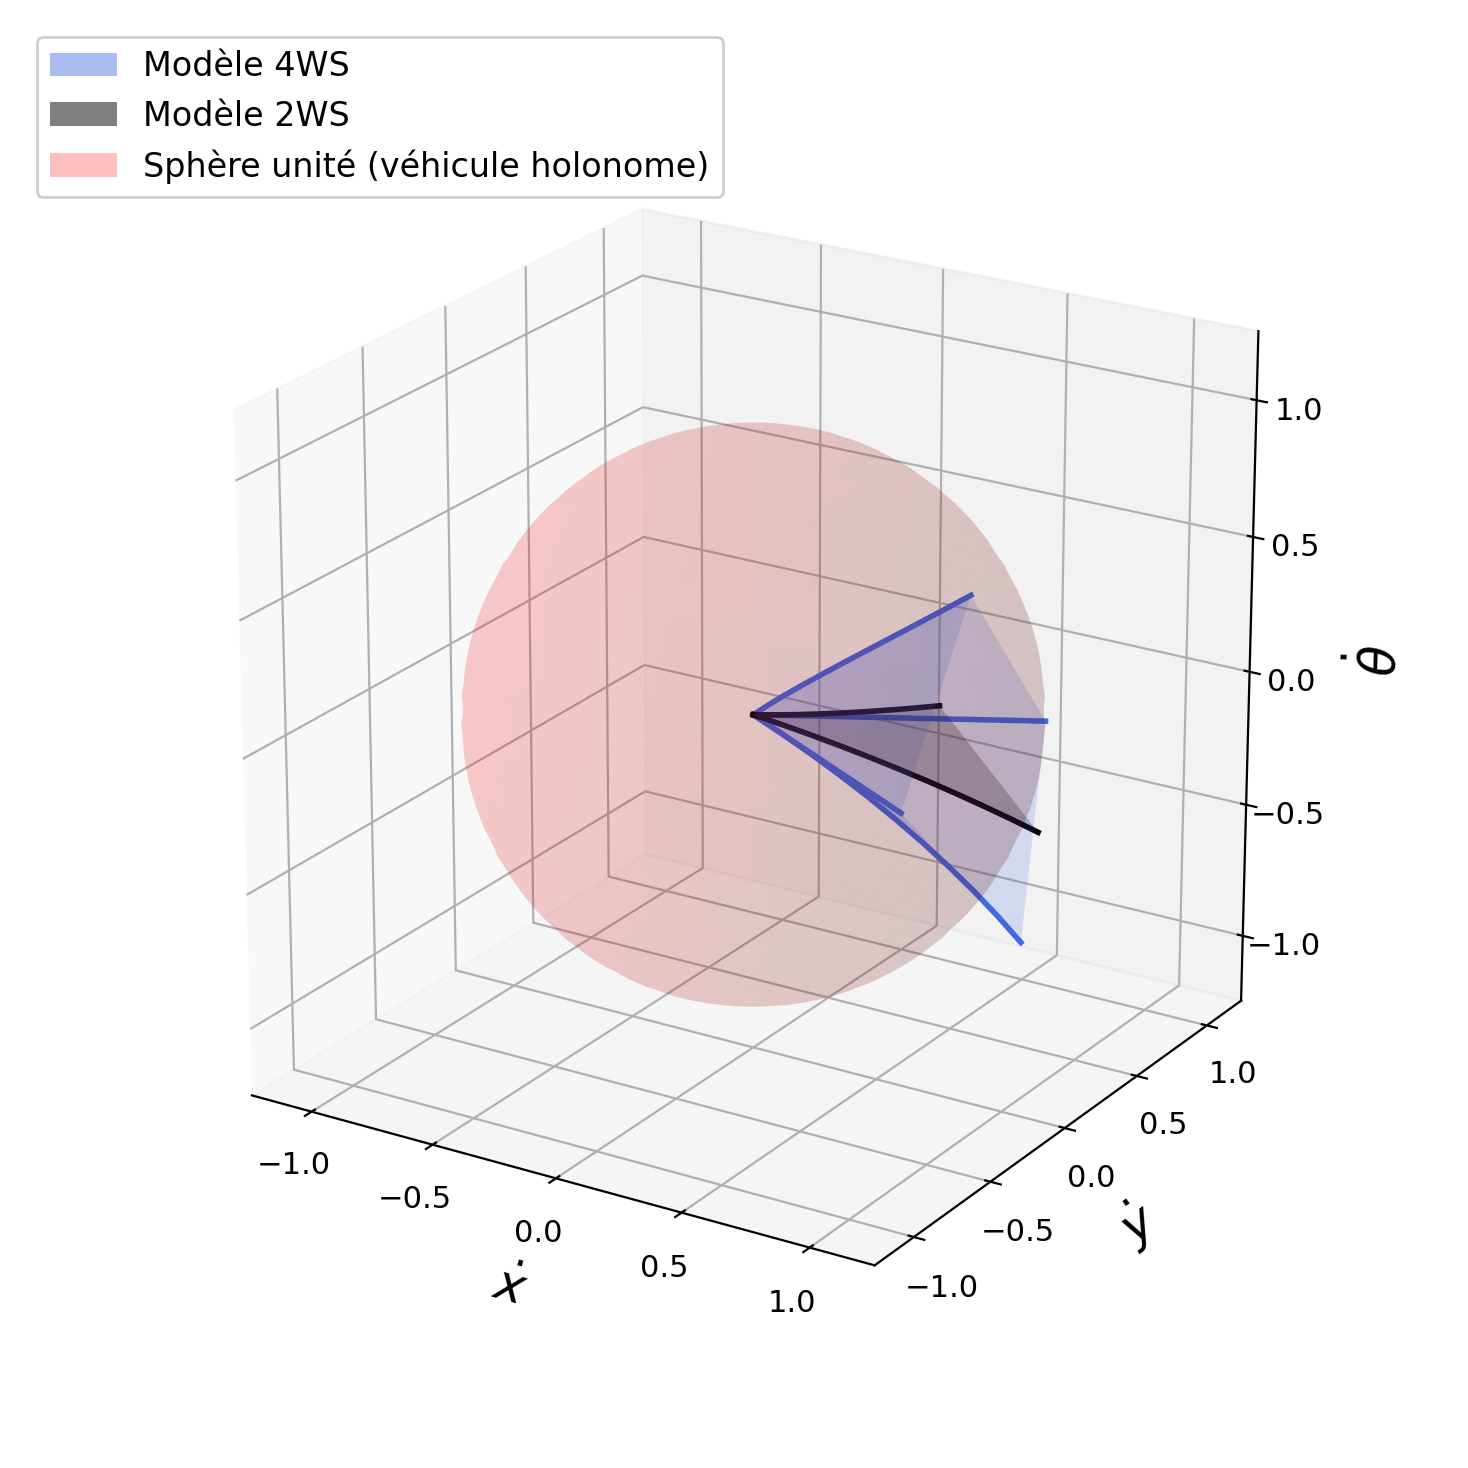

In [7]:
from shfm import generators as GEN
from IPython.display import Image, display

# Tissot's indicatrix.
# The script lives in generators/.
GEN.run("tissot")
display(Image(GEN.figure_path("tissot_d_improved.png")))

<a id='5'></a>
## 5. Minimum turning radius

Steering the rear axle against the front one turns the chassis faster. The
circle followed by the rear-axle centre then has the radius

$$ R_{\min} = \frac{L}{\cos\psi^{*}\,(\tan\varphi^{*} + \tan\psi^{*})} $$

as long as $\varphi^{*} + \psi^{*} \le \pi/2$; beyond, a smaller rear angle
turns tighter than full lock. What halves when both axles take the same
saturation is $L / (\tan\varphi^{*} + \tan\psi^{*})$, the distance from the
centre of rotation to the axis of the vehicle, which is also the radius
followed by the middle of the wheelbase.

We draw, for a left turn at the saturation of 0.5 rad, the circle
followed by the rear-axle centre with the rear axle locked (2WS) and steered
against the front one (4WS), with their centres of rotation.

2WS (rear axle locked)     R_min = 2.53 m   (centre of rotation to axis: 2.53 m)
4WS (counter-phase)        R_min = 1.44 m   (centre of rotation to axis: 1.26 m)


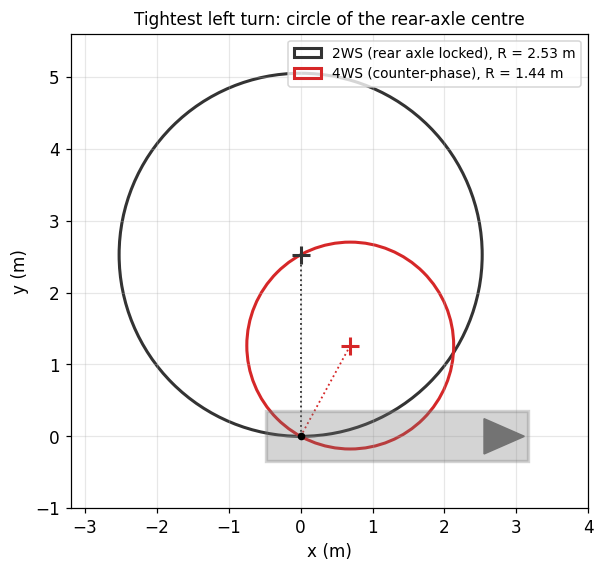

In [8]:
fig, ax = plt.subplots(figsize=(6.6, 5.6))
for psi_max, label, colour in [(0.0, "2WS (rear axle locked)", "0.2"),
                               (d, "4WS (counter-phase)", "tab:red")]:
    axis = v.wheelbase / (np.tan(d) + np.tan(psi_max))
    R = axis / np.cos(psi_max)
    print("%-26s R_min = %.2f m   (centre of rotation to axis: %.2f m)"
          % (label, R, axis))
    # Turning left, the rear axle steers to the right (psi = -phi), so the
    # rear-axle centre moves at -psi_max from the heading; the centre of
    # rotation lies on its left, at the distance R.
    cx, cy = R * np.sin(psi_max), R * np.cos(psi_max)
    ax.add_patch(plt.Circle((cx, cy), R, fill=False, color=colour, lw=2,
                            label="%s, R = %.2f m" % (label, R)))
    ax.plot(cx, cy, "+", color=colour, ms=12, mew=2)
    ax.plot([cx, 0], [cy, 0], ":", color=colour, lw=1.2)
draw_pose(ax, 0, 0, 0, v, 1.0, color="0.45")
ax.plot(0, 0, "o", color="k", ms=4, zorder=9)
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlim(-3.2, 4.0); ax.set_ylim(-1.0, 5.6)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Tightest left turn: circle of the rear-axle centre", fontsize=11)
save(fig, "01_turning_radius"); plt.show()

This smaller radius gives access to passages that a car-like vehicle cannot
use; notebook 5 shows a concrete case.

---

Previous: [0. Overview](00_overview.ipynb)
Next: [2. Collision and configuration space](02_collision_and_configuration_space.ipynb)